In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Find the project folder
root = Path.cwd().resolve()

while not (root / "data/processed/cleaned_data.csv").exists():
    if root == root.parent:
        raise FileNotFoundError("Cannot find cleaned_data.csv")
    root = root.parent

# Load the cleaned dataset
df = pd.read_csv(
    root / "data/processed/cleaned_data.csv"
)

# Convert month to a date
df["month"] = pd.to_datetime(df["month"])
df = df.sort_values("month").reset_index(drop=True)

# Create the graph output folder
output_dir = root / "outputs/eda"
output_dir.mkdir(parents=True, exist_ok=True)

# Display the first 5 rows
df.head()

,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,conversions,average_price_index,promotion_discount_pct,competitor_pressure_index_0_100,economic_sentiment_index_0_100,lkr_usd_exchange_rate,inflation_proxy_index,seasonal_demand_index,public_holiday_count,data_type
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762,3890003,2467793,1836858,1700676,1813444,...,1210051,0.998,7.27,49.6,56.8,324.42,1.000,1.08,2,SYNTHETIC
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574,5062635,2962576,2254198,1922384,2941194,...,664746,1.017,9.47,51.0,58.4,335.92,1.012,0.96,6,SYNTHETIC
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091,3746337,4080535,2363737,1720670,2063917,...,380625,1.011,6.83,45.9,60.6,328.66,1.024,1.00,2,SYNTHETIC
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550,3690115,3390558,2595121,1217450,3091430,...,1228413,1.017,21.52,31.2,54.5,325.60,1.037,1.19,6,SYNTHETIC
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723,5333813,3240078,2343364,1568285,3525300,...,562986,1.014,1.95,53.0,56.5,330.03,1.049,1.10,3,SYNTHETIC


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (36, 25)

Column Names:
['month', 'country', 'brand_category', 'region_scope', 'tv_spend_lkr', 'facebook_instagram_spend_lkr', 'google_search_spend_lkr', 'youtube_spend_lkr', 'radio_spend_lkr', 'outdoor_spend_lkr', 'total_ad_spend_lkr', 'sales_revenue_lkr', 'units_sold', 'impressions', 'clicks', 'conversions', 'average_price_index', 'promotion_discount_pct', 'competitor_pressure_index_0_100', 'economic_sentiment_index_0_100', 'lkr_usd_exchange_rate', 'inflation_proxy_index', 'seasonal_demand_index', 'public_holiday_count', 'data_type']

Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 25 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   month                            36 non-null     datetime64[us]
 1   country                          36 non-null     str           
 2   brand_category                   36 non-null     str     

,month,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,total_ad_spend_lkr,sales_revenue_lkr,units_sold,...,clicks,conversions,average_price_index,promotion_discount_pct,competitor_pressure_index_0_100,economic_sentiment_index_0_100,lkr_usd_exchange_rate,inflation_proxy_index,seasonal_demand_index,public_holiday_count
count,36,3.600000e+01,3.600000e+01,3.600000e+01,3.600000e+01,3.600000e+01,3.600000e+01,3.600000e+01,3.600000e+01,36.000000,...,3.600000e+01,3.600000e+01,36.000000,36.000000,36.000000,36.000000,36.000000,36.000000,36.000000,36.000000
mean,2024-06-16 02:40:00,4.360118e+06,4.398434e+06,3.315365e+06,2.219826e+06,1.669667e+06,2.612717e+06,1.857613e+07,8.509194e+07,152975.500000,...,3.134397e+07,1.156680e+06,1.104639,11.637778,47.308333,48.733333,335.673056,1.243111,1.046667,4.277778
min,2023-01-01 00:00:00,2.638465e+06,3.067341e+06,2.162014e+06,1.476724e+06,1.217450e+06,1.727984e+06,1.353442e+07,6.872716e+07,112715.000000,...,9.184483e+06,3.583500e+05,0.998000,1.950000,28.000000,26.100000,324.420000,1.000000,0.950000,1.000000
25%,2023-09-23 12:00:00,3.846029e+06,3.732282e+06,2.907149e+06,1.882028e+06,1.459317e+06,2.052059e+06,1.597031e+07,8.134299e+07,137041.250000,...,2.256742e+07,6.157125e+05,1.052750,7.235000,38.850000,40.300000,329.940000,1.110750,0.987500,3.000000
50%,2024-06-16 00:00:00,4.352655e+06,4.490288e+06,3.249230e+06,2.160448e+06,1.653602e+06,2.516048e+06,1.909133e+07,8.475952e+07,152151.000000,...,2.890221e+07,9.309500e+05,1.108000,11.115000,48.450000,46.400000,336.505000,1.234500,1.010000,4.000000
75%,2025-03-08 18:00:00,4.920907e+06,4.952398e+06,3.907576e+06,2.458515e+06,1.898464e+06,3.176403e+06,2.108804e+07,8.882893e+07,169776.250000,...,4.180911e+07,1.332412e+06,1.156250,16.352500,54.525000,57.525000,339.322500,1.370000,1.085000,6.000000
max,2025-12-01 00:00:00,6.020432e+06,6.030031e+06,5.096864e+06,3.178264e+06,2.169012e+06,3.690845e+06,2.273382e+07,1.007122e+08,203031.000000,...,6.380120e+07,3.101443e+06,1.214000,28.220000,65.600000,70.100000,348.070000,1.518000,1.240000,8.000000
std,NaN,8.641465e+05,7.736826e+05,7.196457e+05,4.456069e+05,2.728982e+05,6.325274e+05,2.803202e+06,7.642101e+06,24743.534398,...,1.390015e+07,7.509588e+05,0.063258,6.005891,10.217391,12.315101,6.163758,0.156092,0.088544,1.845630



Missing Values:
month                              0
country                            0
brand_category                     0
region_scope                       0
tv_spend_lkr                       0
facebook_instagram_spend_lkr       0
google_search_spend_lkr            0
youtube_spend_lkr                  0
radio_spend_lkr                    0
outdoor_spend_lkr                  0
total_ad_spend_lkr                 0
sales_revenue_lkr                  0
units_sold                         0
impressions                        0
clicks                             0
conversions                        0
average_price_index                0
promotion_discount_pct             0
competitor_pressure_index_0_100    0
economic_sentiment_index_0_100     0
lkr_usd_exchange_rate              0
inflation_proxy_index              0
seasonal_demand_index              0
public_holiday_count               0
data_type                          0
dtype: int64


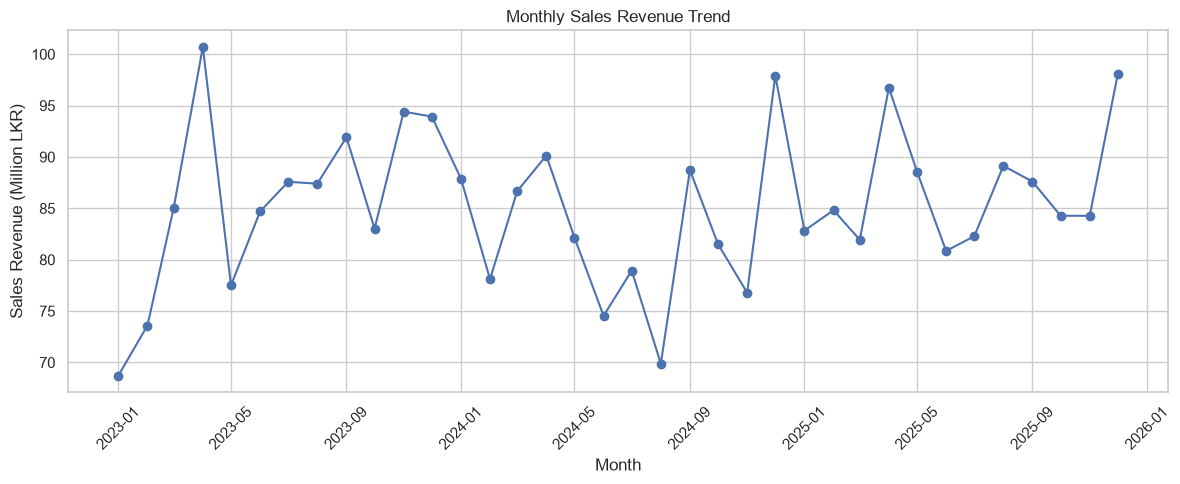

In [3]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["month"],
    df["sales_revenue_lkr"] / 1_000_000,
    marker="o"
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Sales Revenue (Million LKR)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(output_dir / "01_monthly_sales_trend.png")
plt.show()

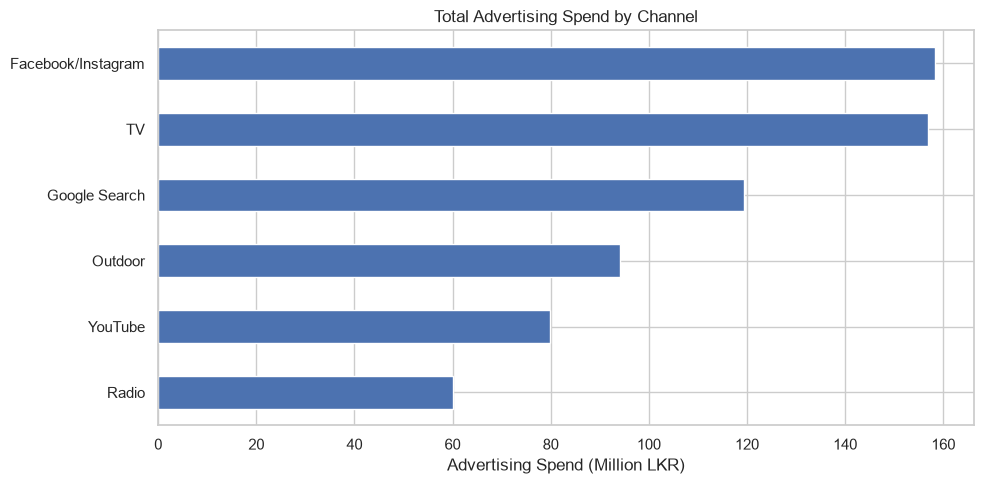

In [4]:
channels = {
    "tv_spend_lkr": "TV",
    "facebook_instagram_spend_lkr": "Facebook/Instagram",
    "google_search_spend_lkr": "Google Search",
    "youtube_spend_lkr": "YouTube",
    "radio_spend_lkr": "Radio",
    "outdoor_spend_lkr": "Outdoor"
}

channel_spend = df[list(channels)].sum()
channel_spend.index = channel_spend.index.map(channels)
channel_spend = channel_spend.sort_values()

plt.figure(figsize=(10, 5))
channel_spend.div(1_000_000).plot(kind="barh")

plt.title("Total Advertising Spend by Channel")
plt.xlabel("Advertising Spend (Million LKR)")
plt.tight_layout()

plt.savefig(output_dir / "02_channel_spending.png")
plt.show()

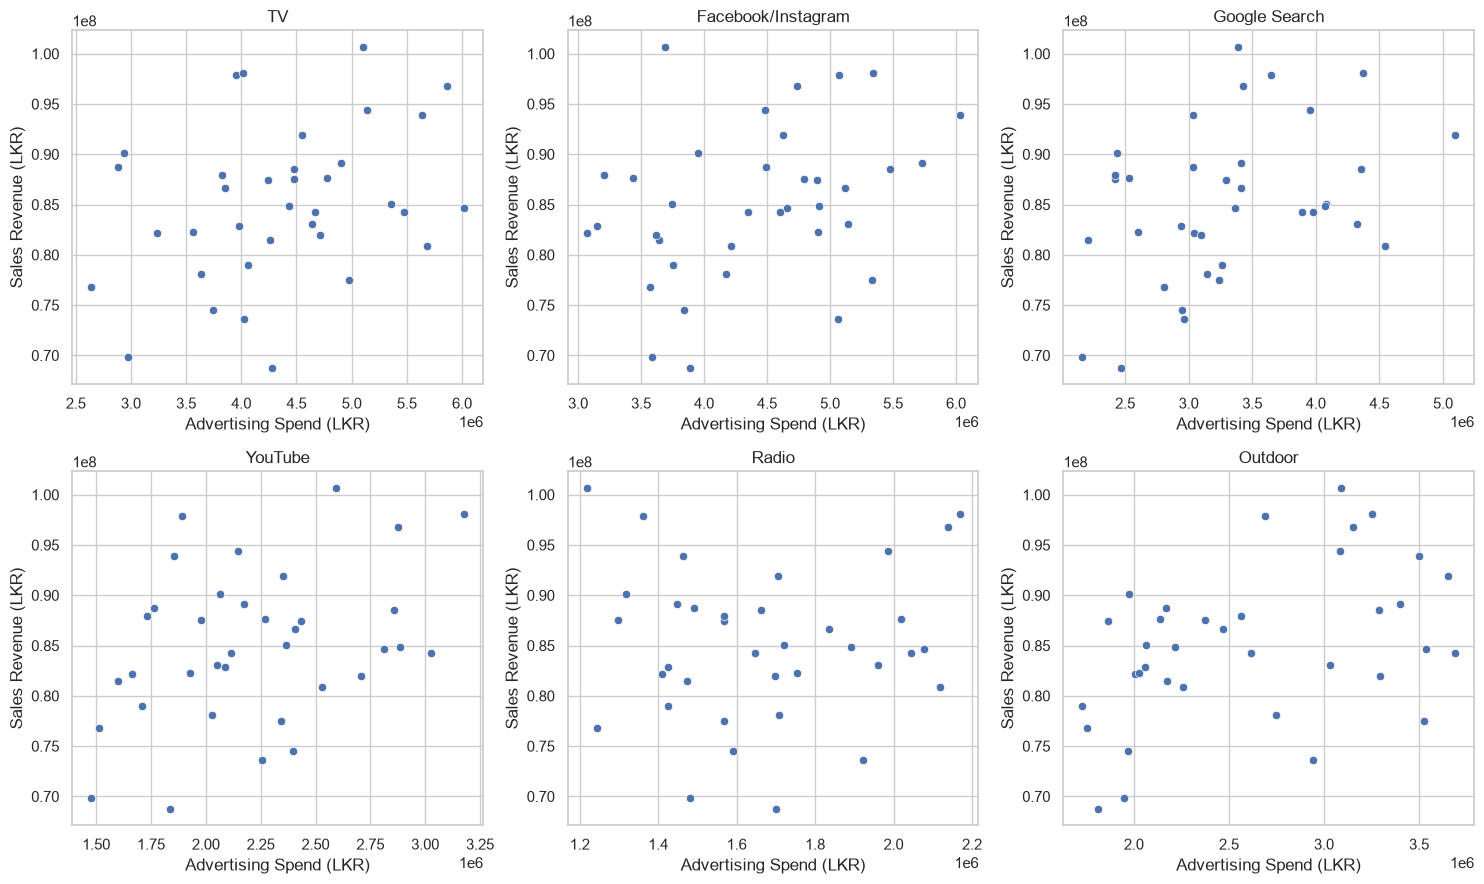

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (column, name) in zip(axes.flat, channels.items()):
    sns.scatterplot(
        data=df,
        x=column,
        y="sales_revenue_lkr",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Advertising Spend (LKR)")
    ax.set_ylabel("Sales Revenue (LKR)")

plt.tight_layout()
plt.savefig(output_dir / "03_spend_vs_sales.png")
plt.show()

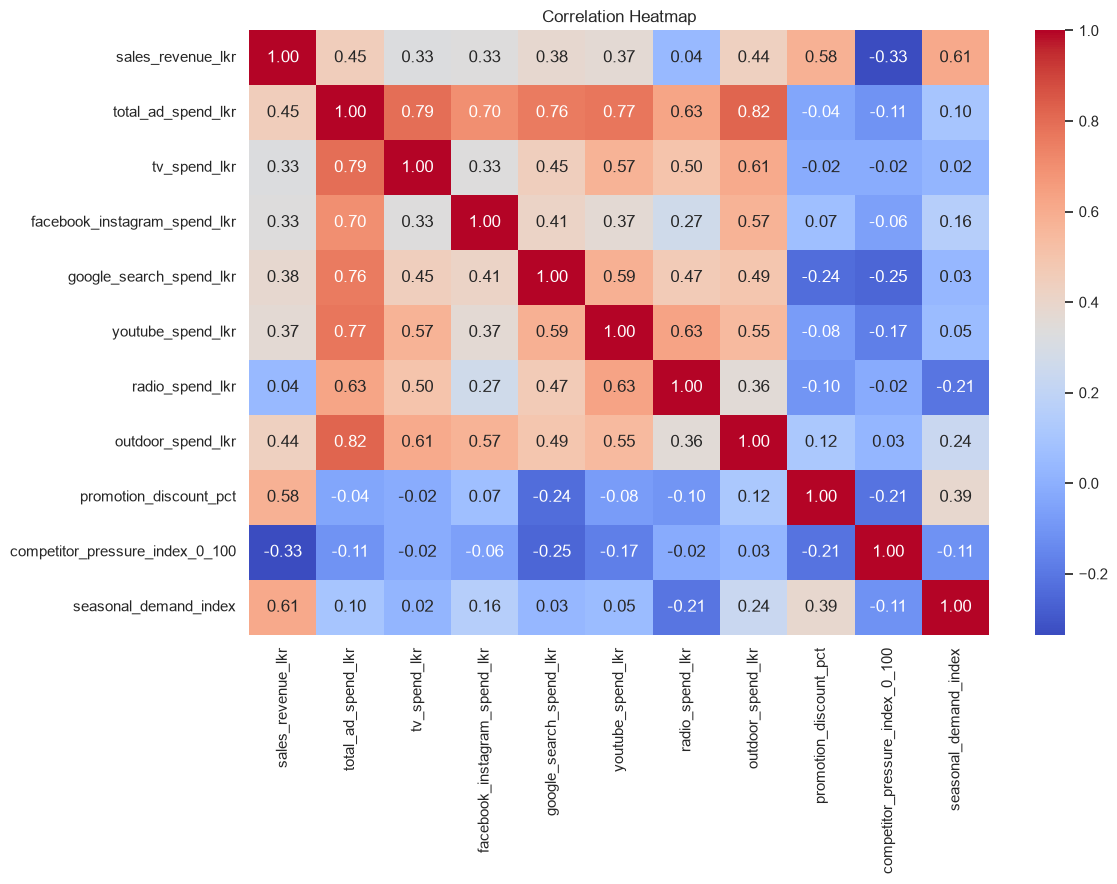

In [6]:
correlation_columns = [
    "sales_revenue_lkr",
    "total_ad_spend_lkr",
    *channels.keys(),
    "promotion_discount_pct",
    "competitor_pressure_index_0_100",
    "seasonal_demand_index"
]

correlation = df[correlation_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig(output_dir / "04_correlation_heatmap.png")
plt.show()

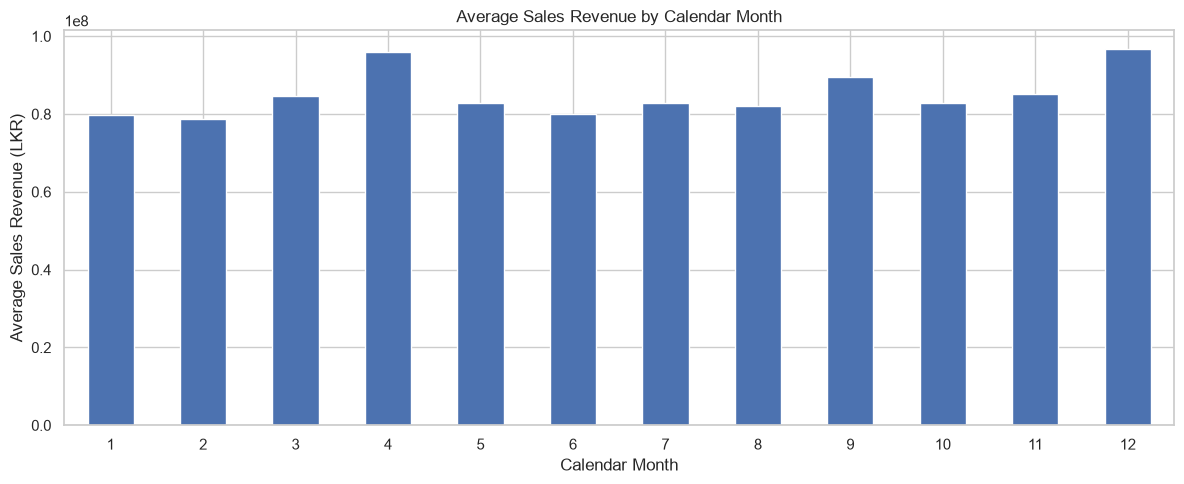

In [7]:
df["calendar_month"] = df["month"].dt.month

seasonal_sales = df.groupby(
    "calendar_month"
)["sales_revenue_lkr"].mean()

plt.figure(figsize=(12, 5))

seasonal_sales.plot(kind="bar")

plt.title("Average Sales Revenue by Calendar Month")
plt.xlabel("Calendar Month")
plt.ylabel("Average Sales Revenue (LKR)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(output_dir / "05_seasonal_sales.png")
plt.show()

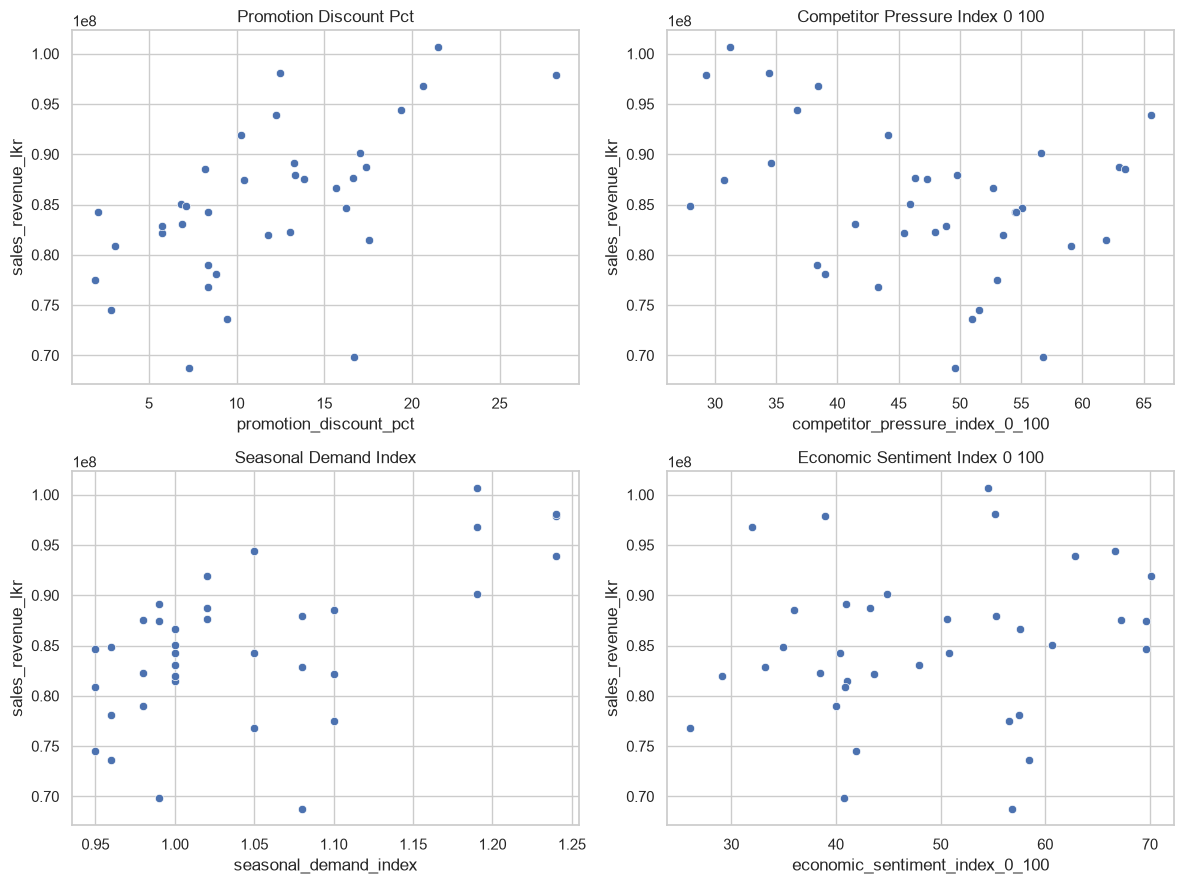

In [8]:
external_factors = [
    "promotion_discount_pct",
    "competitor_pressure_index_0_100",
    "seasonal_demand_index",
    "economic_sentiment_index_0_100"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, factor in zip(axes.flat, external_factors):
    sns.scatterplot(
        data=df,
        x=factor,
        y="sales_revenue_lkr",
        ax=ax
    )

    ax.set_title(factor.replace("_", " ").title())

plt.tight_layout()

plt.savefig(output_dir / "06_external_factors.png")
plt.show()

In [9]:
print("Saved EDA graphs:")

for file in sorted(output_dir.glob("*.png")):
    print(file.name)

Saved EDA graphs:
01_monthly_sales_trend.png
02_channel_spending.png
03_spend_vs_sales.png
04_correlation_heatmap.png
05_seasonal_sales.png
06_external_factors.png
